## Node2Vec:

---

In [1]:
# %pip install node2vec

In [2]:
import pickle

with open('../01-Dataset/graph_network.pkl', 'rb') as file:
    G = pickle.load(file)

In [3]:
from node2vec import Node2Vec

node2vec = Node2Vec(
    G, 
    seed=42, 
    dimensions=64, 
    walk_length=30, 
    num_walks=200, 
    workers=4 # n_jobs
)

Computing transition probabilities:   0%|          | 0/150 [00:00<?, ?it/s]

In [4]:
model = node2vec.fit(
    window=10,
    min_count=1,
    batch_words=4
)

In [5]:
embeddings = model.wv
print(f"Successfully embedded {len(embeddings.key_to_index)} nodes into 64-dimensional space.")
print("150 nodes, each represented by 64 dimensional vector")

Successfully embedded 150 nodes into 64-dimensional space.
150 nodes, each represented by 64 dimensional vector


---

## PCA:

In [16]:
print(type(embeddings))

<class 'gensim.models.keyedvectors.KeyedVectors'>


In [ ]:
import numpy as np

# Converting from strings to keys
node_id = list(model.wv.key_to_index.keys())

# Sorting
node_id.sort(key=int)
vectors_64d = np.array([model.wv[str(node)] for node in node_id])

In [21]:
print(f"Class type: {type(vectors_64d)}")
print(f"Shape: {vectors_64d.shape}")


Class type: <class 'numpy.ndarray'>
Shape: (150, 64)


In [20]:
display(vectors_64d)


array([[ 0.09044912, -0.10967978,  0.1536599 , ...,  0.09393129,
         0.05602027,  0.10250119],
       [ 0.15584704, -0.4211618 , -0.16994749, ..., -0.2069781 ,
        -0.06455316, -0.12036351],
       [ 0.06968494, -0.13709871,  0.11375149, ..., -0.11077041,
        -0.06470478,  0.00240824],
       ...,
       [ 0.24874681, -0.45229465, -0.16576996, ..., -0.07598718,
        -0.02910185, -0.15111277],
       [ 0.22938667, -0.14660703,  0.01780559, ..., -0.02362148,
         0.06931197,  0.00300783],
       [ 0.22047457, -0.54397756, -0.07038456, ..., -0.1273602 ,
         0.01558757, -0.10172297]], dtype=float32)

In [ ]:
# Loading the pyshcological profile labels:

node_labels = np.load('../01-Dataset/node_labels.npy')
display(node_labels)

array([2, 1, 2, 1, 0, 1, 0, 0, 2, 1, 1, 1, 1, 1, 0, 2, 2, 2, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 0, 2, 1, 0, 1, 1, 2, 1, 0, 2, 0, 1, 2, 1, 2,
       2, 2, 1, 0, 0, 2, 2, 2, 0, 2, 0, 0, 1, 2, 2, 1, 2, 1, 0, 2, 2, 0,
       1, 0, 1, 1, 0, 2, 2, 2, 0, 2, 0, 1, 0, 1, 2, 1, 1, 1, 0, 2, 1, 0,
       2, 0, 1, 0, 2, 2, 0, 2, 0, 0, 2, 2, 0, 2, 0, 0, 0, 0, 2, 1, 0, 0,
       0, 2, 2, 0, 2, 0, 0, 1, 1, 1, 0, 2, 2, 1, 2, 1, 0, 0, 0, 2, 0, 1,
       1, 1, 2, 0, 2, 1, 1, 2, 0, 0, 2, 2, 2, 2, 1, 1, 2, 1], dtype=int64)

In [24]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

In [26]:
vectors_2d = pca.fit_transform(vectors_64d)
print(f"Shape: {vectors_2d.shape}")

Shape: (150, 2)


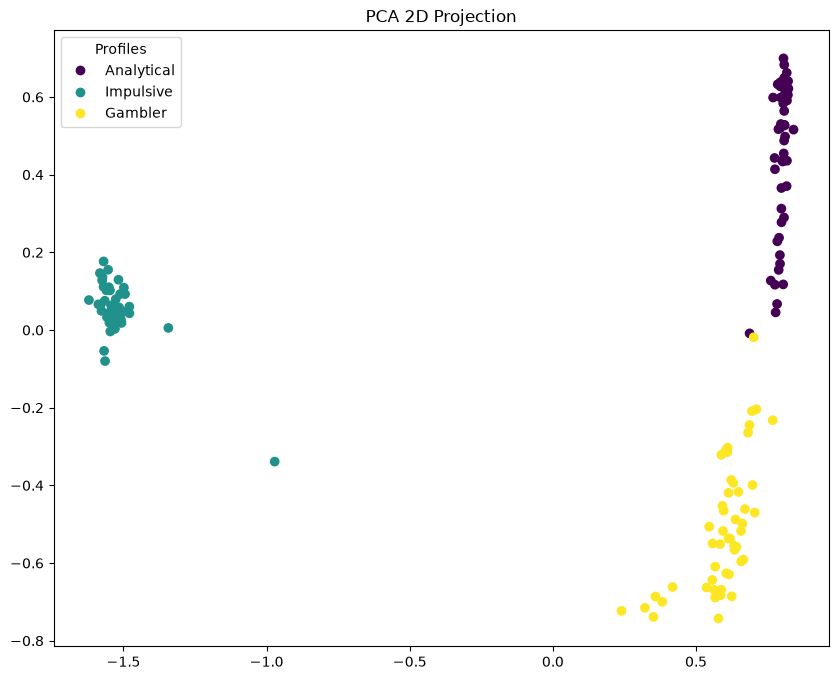

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

scatter = plt.scatter(x=vectors_2d[:, 0], y=vectors_2d[:, 1], c=node_labels)

profiles = ['Analytical', 'Impulsive', 'Gambler']
plt.legend(handles=scatter.legend_elements()[0], labels=profiles, title='Profiles')
plt.title('PCA 2D Projection')

plt.show()